# Credence AI – Credit Card Default Prediction

**Stakeholder:** Credit Portfolio Strategist
**Goal:** predict whether a credit card customer will default on next month's payment (`default.payment.next.month`: 0 = no default, 1 = default) from 23 historical financial and repayment features.

This notebook is **self-contained** so it runs unchanged on **Kaggle Notebooks** (add the *Default of Credit Card Clients* dataset as input) or locally from the project's `notebooks/` folder. It mirrors the production pipeline in `ml/` exactly: same features, same split, same preprocessing, same models.

**Contents**
1. Setup & data loading
2. Exploratory data analysis
3. Preprocessing design (and why)
4. Model training & cross-validated tuning
5. Evaluation – with focus on the default class
6. Decision threshold & error costs
7. Model selection & conclusion

## 1. Setup & data loading

In [1]:
import glob, json, os, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

# Consistent, colour-blind-safe styling
NO_DEFAULT, DEFAULT = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
CLASS_PALETTE = {0: NO_DEFAULT, 1: DEFAULT}
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#2a78d6", "#0d3a73"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#e6e5e0", "figure.dpi": 100})

scikit-learn 1.9.1 | pandas 3.1.1


In [2]:
# Locate the dataset: Kaggle input folder first, then the local project layout.
CANDIDATES = (
    glob.glob("/kaggle/input/**/*.csv", recursive=True)
    + ["../data/raw/default of credit card clients.csv", "data/raw/default of credit card clients.csv"]
)
CSV_PATH = next(p for p in CANDIDATES if os.path.exists(p) and "credit" in p.lower())
ON_KAGGLE = CSV_PATH.startswith("/kaggle/")
OUTPUT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Dataset:", CSV_PATH)

# The original UCI export has an extra placeholder header (",X1,...,Y") above the real one.
with open(CSV_PATH, encoding="utf-8-sig") as f:
    first_line = f.readline()
header_row = 0 if "LIMIT_BAL" in first_line else 1
print("First line:", first_line.strip()[:60], "...  -> header row =", header_row)

raw = pd.read_csv(CSV_PATH, header=header_row)
raw.head()

Dataset: ../data/raw/default of credit card clients.csv
First line: ,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17, ...  -> header row = 1


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
TARGET = "default.payment.next.month"
df = raw.rename(columns={"default payment next month": TARGET, "PAY_1": "PAY_0"})
if "ID" in df.columns:
    df = df.drop(columns="ID")          # identifier, not a predictive feature

FEATURES = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
            "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
            "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
            "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]
CATEGORICAL = ["SEX", "EDUCATION", "MARRIAGE"]
REPAYMENT_STATUS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
MONETARY = ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
CONTINUOUS = ["AGE"]
assert len(FEATURES) == 23 and sorted(FEATURES) == sorted(CATEGORICAL + REPAYMENT_STATUS + MONETARY + CONTINUOUS)

df = df[FEATURES + [TARGET]]
print("Raw shape (incl. ID):", raw.shape, "| modelling shape:", df.shape)

Raw shape (incl. ID): (30000, 25) | modelling shape: (30000, 24)


## 2. Exploratory data analysis
### 2.1 Structure, data types, missing values, duplicates

In [4]:
print("Columns:", list(df.columns))
print("\nData types:\n", df.dtypes.value_counts())
print("\nMissing values per column (total):", int(df.isna().sum().sum()))
print("Duplicate rows (excluding ID):", int(df.duplicated().sum()))

Columns: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']

Data types:
 int64    24
Name: count, dtype: int64

Missing values per column (total): 0
Duplicate rows (excluding ID): 35


*Findings:* all 24 columns are integer-coded, there are **no missing values**, and **35 rows** are duplicates once `ID` is removed. Every row has a distinct `ID`, so these are separate customers who happen to have identical records (mostly inactive accounts with zero bills and payments). They are **kept**: removing them would drop real customers, and 35 of 30,000 rows cannot bias the model.

### 2.2 Descriptive statistics

In [5]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_0,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_5,30000.0,-0.3,1.1,-2.0,-1.0,0.0,0.0,8.0


### 2.3 Target class distribution

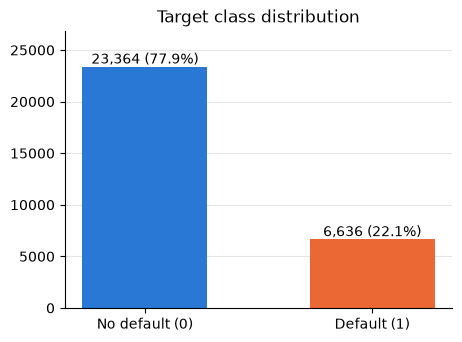

In [6]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(["No default (0)", "Default (1)"], counts.values, color=[NO_DEFAULT, DEFAULT], width=0.55)
for b, v in zip(bars, counts.values):
    ax.annotate(f"{v:,} ({v/counts.sum():.1%})", (b.get_x() + b.get_width()/2, v), ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.15); ax.set_title("Target class distribution"); ax.grid(axis="x", visible=False)
plt.show()

The data is **imbalanced (≈78% / 22%)**. A model that always predicts "no default" scores 77.9% accuracy while catching zero defaulters, so **accuracy is a misleading metric here**. We will use stratified splitting, class weighting, and default-class precision/recall/F1 plus ROC-AUC.

### 2.4 Categorical codes

In [7]:
for c in CATEGORICAL + ["PAY_0"]:
    print(c, dict(df[c].value_counts().sort_index()))

SEX {1: np.int64(11888), 2: np.int64(18112)}
EDUCATION {0: np.int64(14), 1: np.int64(10585), 2: np.int64(14030), 3: np.int64(4917), 4: np.int64(123), 5: np.int64(280), 6: np.int64(51)}
MARRIAGE {0: np.int64(54), 1: np.int64(13659), 2: np.int64(15964), 3: np.int64(323)}
PAY_0 {-2: np.int64(2759), -1: np.int64(5686), 0: np.int64(14737), 1: np.int64(3688), 2: np.int64(2667), 3: np.int64(322), 4: np.int64(76), 5: np.int64(26), 6: np.int64(11), 7: np.int64(9), 8: np.int64(19)}


* `EDUCATION` documents 1–4 (graduate school, university, high school, others), but the data also contains **0, 5, 6** (345 rows).
* `MARRIAGE` documents 1–3, but **0** also appears (54 rows).
* `PAY_*` is an **ordinal** repayment status: −2 = no consumption, −1 = paid in full, 0 = revolving credit, 1–8 = months of delay.

We do **not** delete the rows with undocumented codes. Instead the encoder merges any category seen in fewer than 2% of *training* rows into one "infrequent" bucket, which on this data reproduces the documented "others" group.

### 2.5 Feature distributions & outliers

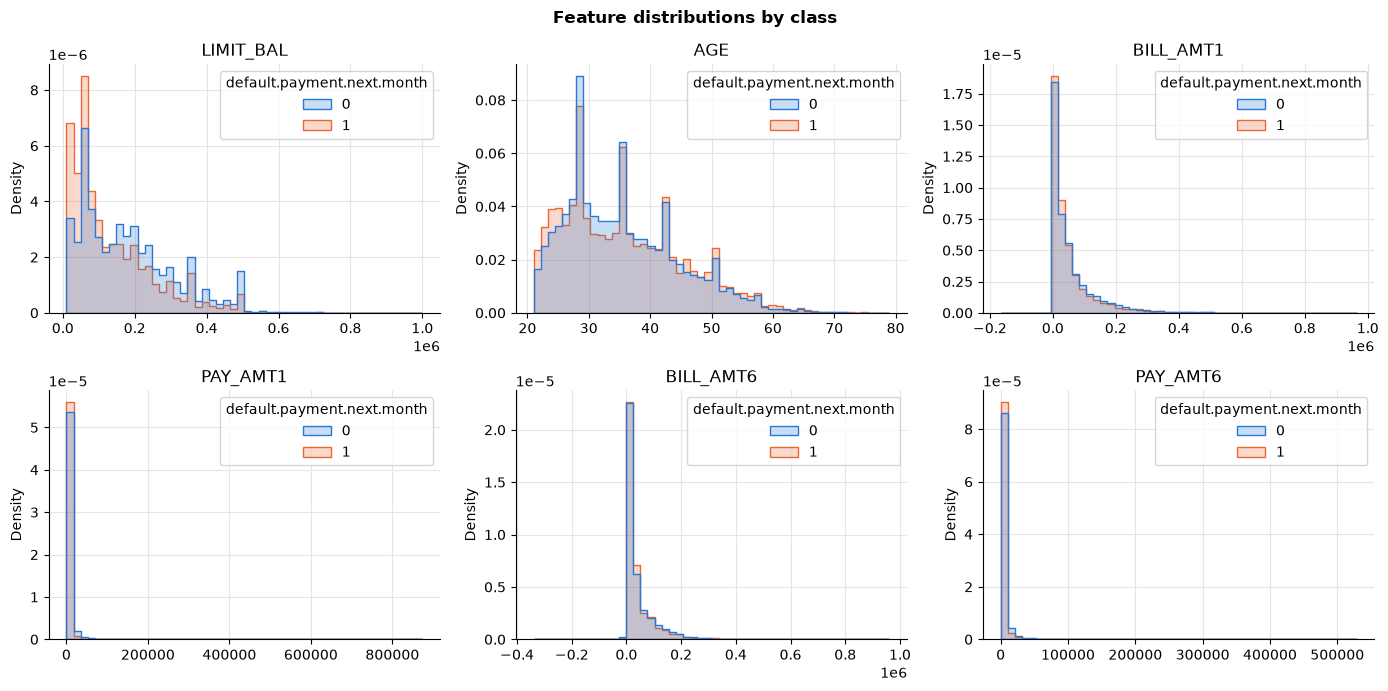

In [8]:
cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "BILL_AMT6", "PAY_AMT6"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(data=df, x=c, hue=TARGET, palette=CLASS_PALETTE, bins=50, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Feature distributions by class", fontweight="bold"); plt.tight_layout(); plt.show()

LIMIT_BAL     167
BILL_AMT1    2400
BILL_AMT2    2395
BILL_AMT3    2469
BILL_AMT4    2622
BILL_AMT5    2725
BILL_AMT6    2693
PAY_AMT1     2745
PAY_AMT2     2714
PAY_AMT3     2598
PAY_AMT4     2994
PAY_AMT5     2945
PAY_AMT6     2958
AGE           272

Negative bill amounts (credit balances): 3932


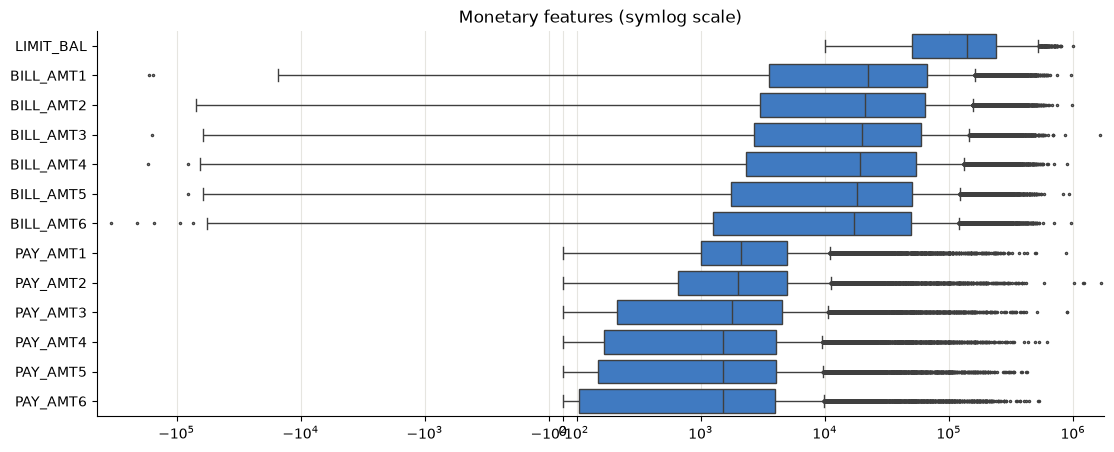

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

outliers = pd.Series({c: iqr_outliers(df[c]) for c in MONETARY + ["AGE"]}, name="IQR outliers")
print(outliers.to_string())
print("\nNegative bill amounts (credit balances):", int((df[[f'BILL_AMT{i}' for i in range(1,7)]] < 0).sum().sum()))

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=df[MONETARY], orient="h", color=NO_DEFAULT, fliersize=1.5, ax=ax)
ax.set_xscale("symlog", linthresh=1000); ax.set_title("Monetary features (symlog scale)"); plt.show()

*Outlier decision:* the monetary features are strongly **right-skewed**, with many IQR "outliers". These are **genuine high-limit / high-spending customers**, not data errors, and they matter to a portfolio strategist, so we **do not remove them**. Instead a **Yeo-Johnson power transform** compresses the skew. Unlike `log`, it also handles the **negative bill amounts** (credit balances).

### 2.6 Correlation analysis

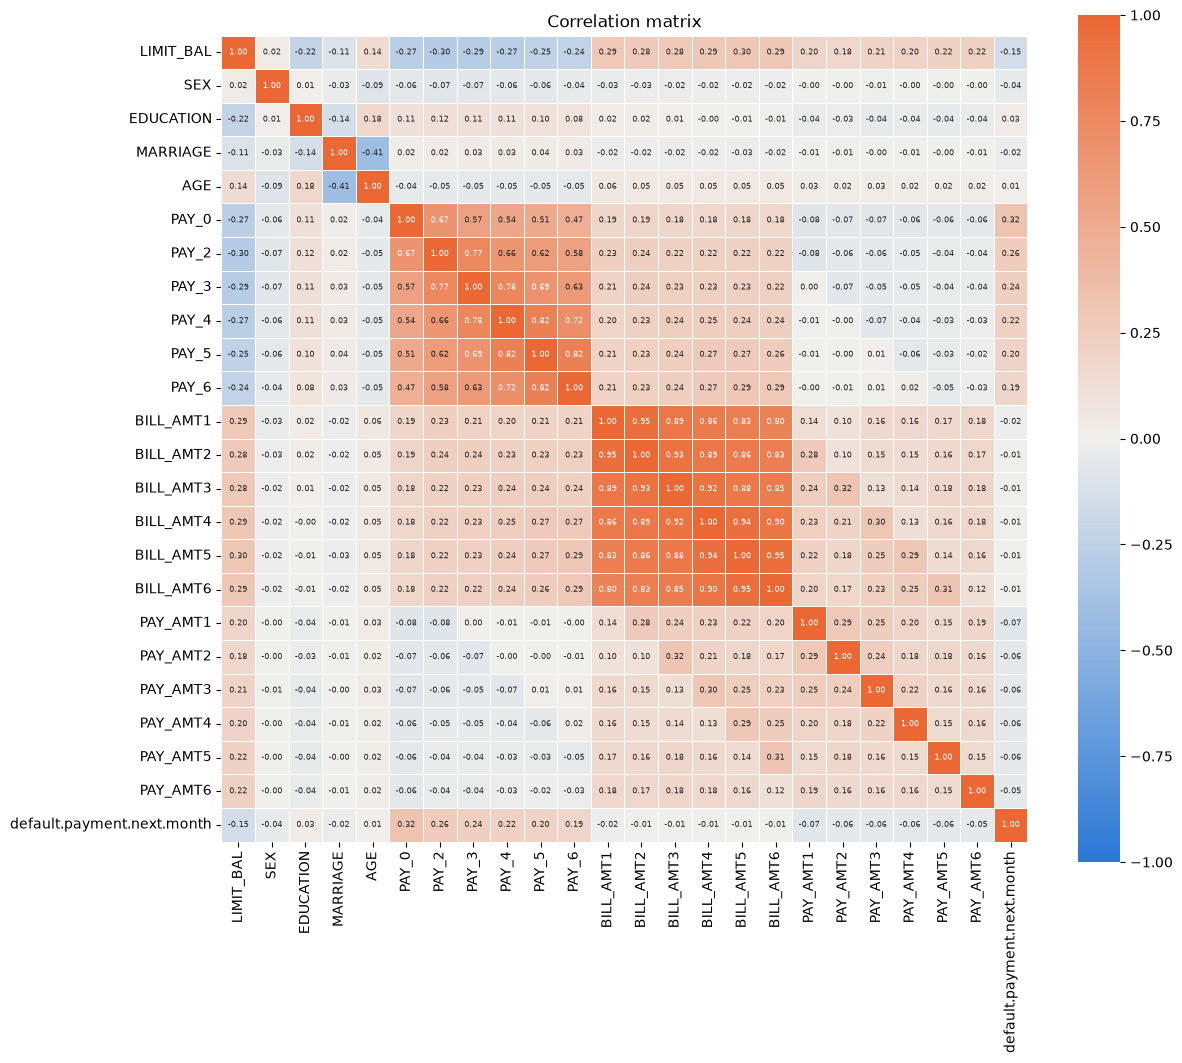

PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
dtype: float64


In [10]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6}, square=True, linewidths=.4, ax=ax)
ax.set_title("Correlation matrix"); plt.show()
print(df[FEATURES].corrwith(df[TARGET]).sort_values(key=np.abs, ascending=False).round(3).head(10))

* The `BILL_AMT1..6` columns are highly inter-correlated (r ≈ 0.8–0.95), and so are the `PAY_*` statuses. That is multicollinearity, but it is not harmful for prediction: tree models are unaffected, and Logistic Regression is regularised (L2). All 23 required features are kept.
* The **repayment status features** correlate most strongly with default (`PAY_0` r ≈ 0.32). `LIMIT_BAL` is negatively correlated: higher credit limits go with lower default risk.

### 2.7 Feature–target relationships

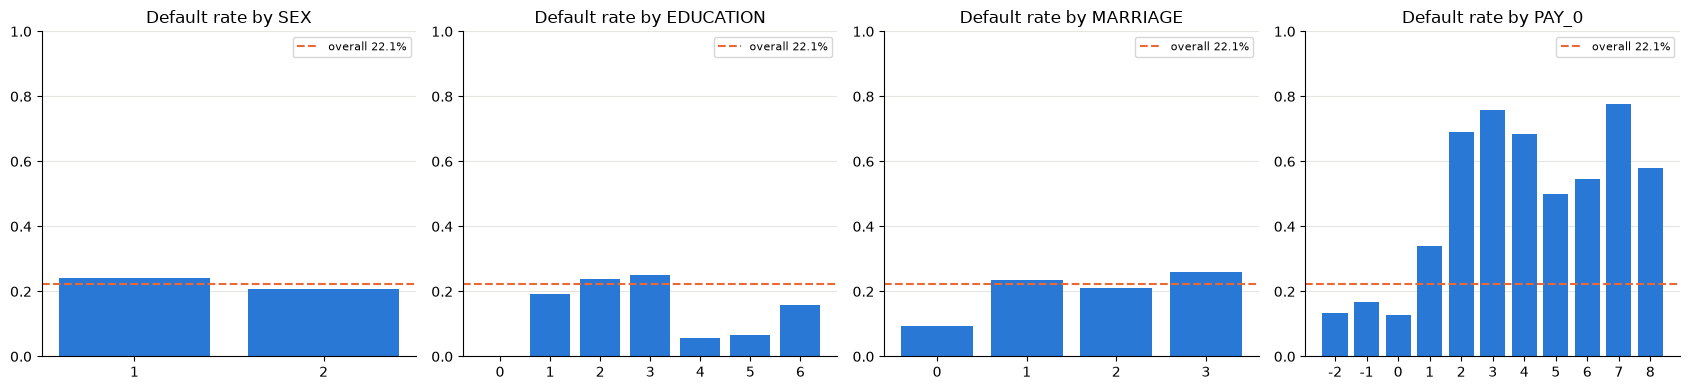

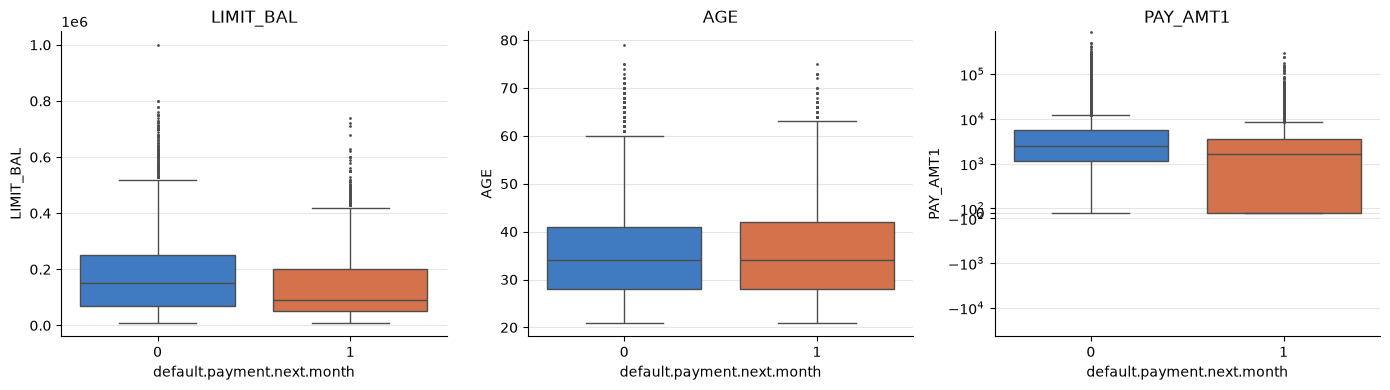

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
overall = df[TARGET].mean()
for ax, c in zip(axes, ["SEX", "EDUCATION", "MARRIAGE", "PAY_0"]):
    g = df.groupby(c)[TARGET].mean()
    ax.bar(g.index.astype(str), g.values, color=NO_DEFAULT)
    ax.axhline(overall, color=DEFAULT, ls="--", label=f"overall {overall:.1%}")
    ax.set_title(f"Default rate by {c}"); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["LIMIT_BAL", "AGE", "PAY_AMT1"]):
    sns.boxplot(data=df, x=TARGET, y=c, hue=TARGET, palette=CLASS_PALETTE, legend=False, ax=ax, fliersize=1)
    if c.startswith("PAY_AMT"): ax.set_yscale("symlog", linthresh=1000)
    ax.set_title(c)
plt.tight_layout(); plt.show()

*Key insights for the Credit Portfolio Strategist:*
* Customers whose **most recent payment (PAY_0) is ≥2 months late default 50–78% of the time**, versus about 13% for customers who pay on time. Recent repayment behaviour is the strongest risk signal.
* Defaulters have **lower credit limits** and make **smaller payments**.
* Demographics (sex, marital status, age) show only weak differences in default rate.

## 3. Preprocessing design

| Feature group | Columns | Transformation | Why |
|---|---|---|---|
| Nominal categorical | SEX, EDUCATION, MARRIAGE | One-hot, rare codes (<2% of train) → "infrequent" bucket, unseen codes → same bucket | Codes have no numeric order; handles undocumented codes without deleting rows |
| Ordinal repayment status | PAY_0, PAY_2..PAY_6 | Kept numeric, StandardScaler | Larger value = longer delay, so the order is meaningful |
| Monetary | LIMIT_BAL, BILL_AMT1-6, PAY_AMT1-6 | Yeo-Johnson power transform + standardise | Heavy skew, extreme values, negative bills |
| Continuous | AGE | StandardScaler | Scale for LR / KNN |

**Leakage prevention:** all transformers sit **inside a scikit-learn `Pipeline`** with the classifier.
* `fit` is called only on the training split.
* During cross-validation the pipeline is re-fit inside each fold.
* The test set is used once, for the final evaluation.

The saved pipeline is what the FastAPI backend loads, so training and inference preprocessing are **identical by construction**.

In [12]:
X, y = df[FEATURES], df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Train {X_train.shape}  default rate {y_train.mean():.4f}")
print(f"Test  {X_test.shape}  default rate {y_test.mean():.4f}")

def build_preprocessor():
    return ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.02,
                                      sparse_output=False), CATEGORICAL),
        ("repayment_status", StandardScaler(), REPAYMENT_STATUS),
        ("monetary", PowerTransformer(method="yeo-johnson", standardize=True), MONETARY),
        ("continuous", StandardScaler(), CONTINUOUS),
    ])

pre = build_preprocessor().fit(X_train)          # fit on TRAIN only
print("\nEncoded feature count:", len(pre.get_feature_names_out()))
print([n for n in pre.get_feature_names_out() if n.startswith("categorical")])

Train (24000, 23)  default rate 0.2212
Test  (6000, 23)  default rate 0.2212



Encoded feature count: 29
['categorical__SEX_1', 'categorical__SEX_2', 'categorical__EDUCATION_1', 'categorical__EDUCATION_2', 'categorical__EDUCATION_3', 'categorical__EDUCATION_infrequent_sklearn', 'categorical__MARRIAGE_1', 'categorical__MARRIAGE_2', 'categorical__MARRIAGE_infrequent_sklearn']


## 4. Model training & cross-validated tuning

Four required algorithms, each tuned with **5-fold stratified CV on the training set**, scoring on **F1 for the default class**:

* **Logistic Regression**: linear, interpretable baseline. `class_weight="balanced"`.
* **Decision Tree**: non-linear and readable. Depth and leaf size are limited to prevent overfitting. `class_weight="balanced"`.
* **Random Forest**: an ensemble of decorrelated trees, robust to outliers and collinearity. `class_weight="balanced_subsample"`.
* **K-Nearest Neighbours**: distance-based, so it needs the scaled features. It has no class-weight option, which matters on imbalanced data (see the results). 24k training rows are computationally fine, so KNN is **not** skipped.

XGBoost is deliberately not used (project constraint).

In [13]:
CANDIDATES = {
    "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
                            {"classifier__C": [0.01, 0.1, 1.0, 10.0]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"classifier__max_depth": [4, 6, 8, 10], "classifier__min_samples_leaf": [20, 50, 100]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=1,
                                             random_state=RANDOM_STATE),
                      {"classifier__max_depth": [8, 12], "classifier__min_samples_leaf": [5, 10, 20]}),
    "K-Nearest Neighbors": (KNeighborsClassifier(),
                            {"classifier__n_neighbors": [15, 31, 51], "classifier__weights": ["uniform", "distance"]}),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"f1": "f1", "roc_auc": "roc_auc", "precision": "precision", "recall": "recall", "accuracy": "accuracy"}

searches = {}
for name, (est, grid) in CANDIDATES.items():
    t = time.perf_counter()
    s = GridSearchCV(Pipeline([("preprocessor", build_preprocessor()), ("classifier", est)]),
                     grid, scoring=scoring, refit="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)
    searches[name] = s
    print(f"{name:<22} best {s.best_params_}  CV F1={s.best_score_:.4f}  ({time.perf_counter()-t:.1f}s)")

Logistic Regression    best {'classifier__C': 0.1}  CV F1=0.5069  (4.3s)


Decision Tree          best {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 50}  CV F1=0.5291  (6.1s)


Random Forest          best {'classifier__max_depth': 12, 'classifier__min_samples_leaf': 5}  CV F1=0.5460  (40.9s)


K-Nearest Neighbors    best {'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}  CV F1=0.4413  (5.5s)


## 5. Evaluation on the held-out test set

In [14]:
def metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"accuracy": accuracy_score(y_true, pred), "precision_1": precision_score(y_true, pred),
            "recall_1": recall_score(y_true, pred), "f1_1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba), "FP": fp, "FN": fn, "TP": tp, "TN": tn}

rows, probas = {}, {}
for name, s in searches.items():
    probas[name] = s.best_estimator_.predict_proba(X_test)[:, 1]
    i = s.best_index_
    rows[name] = {"cv_f1": s.cv_results_["mean_test_f1"][i], "cv_roc_auc": s.cv_results_["mean_test_roc_auc"][i],
                  **{f"test_{k}": v for k, v in metrics(y_test, probas[name]).items()}}
comparison = pd.DataFrame(rows).T
comparison.round(4)

,cv_f1,cv_roc_auc,test_accuracy,test_precision_1,test_recall_1,test_f1_1,test_roc_auc,test_FP,test_FN,test_TP,test_TN
Logistic Regression,0.5069,0.7518,0.7135,0.4044,0.6247,0.4910,0.7405,1221.0,498.0,829.0,3452.0
Decision Tree,0.5291,0.7565,0.7662,0.4759,0.5644,0.5164,0.7481,825.0,578.0,749.0,3848.0
Random Forest,0.5460,0.7819,0.7937,0.5319,0.5599,0.5455,0.7747,654.0,584.0,743.0,4019.0
K-Nearest Neighbors,0.4413,0.7457,0.8085,0.6206,0.3451,0.4436,0.7417,280.0,869.0,458.0,4393.0


In [15]:
for name in searches:
    print(f"===== {name} =====")
    print(classification_report(y_test, (probas[name] >= 0.5).astype(int),
                                target_names=["No default (0)", "Default (1)"], digits=4))

===== Logistic Regression =====
                precision    recall  f1-score   support

No default (0)     0.8739    0.7387    0.8006      4673
   Default (1)     0.4044    0.6247    0.4910      1327

      accuracy                         0.7135      6000
     macro avg     0.6392    0.6817    0.6458      6000
  weighted avg     0.7701    0.7135    0.7322      6000

===== Decision Tree =====
                precision    recall  f1-score   support

No default (0)     0.8694    0.8235    0.8458      4673
   Default (1)     0.4759    0.5644    0.5164      1327

      accuracy                         0.7662      6000
     macro avg     0.6726    0.6939    0.6811      6000
  weighted avg     0.7824    0.7662    0.7729      6000

===== Random Forest =====
                precision    recall  f1-score   support

No default (0)     0.8731    0.8600    0.8665      4673
   Default (1)     0.5319    0.5599    0.5455      1327

      accuracy                         0.7937      6000
     macro a

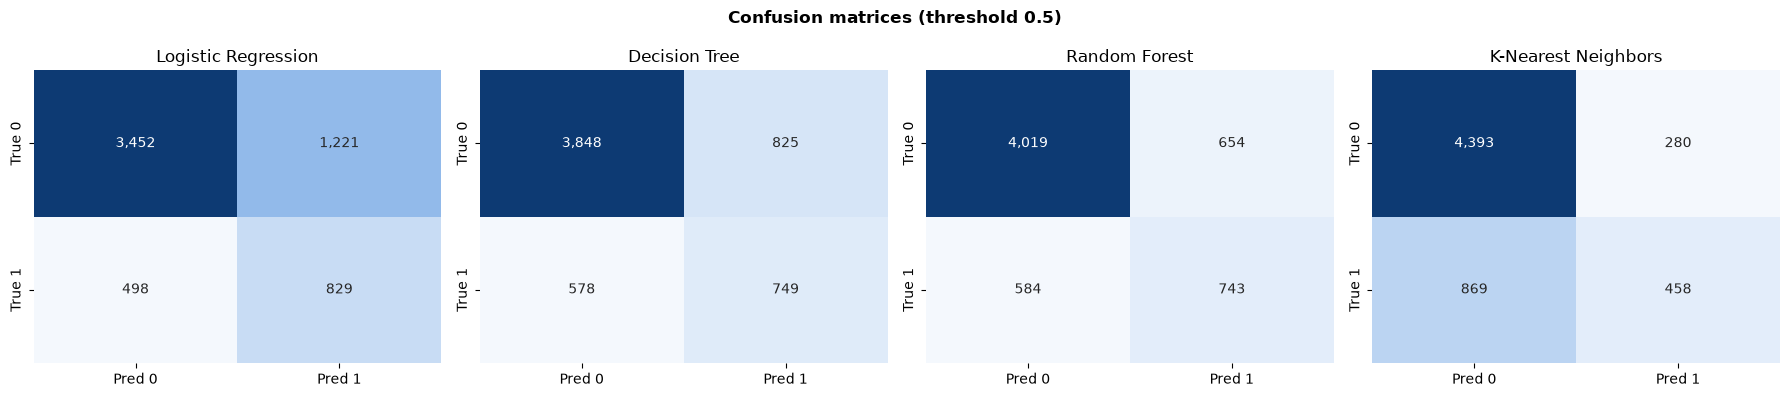

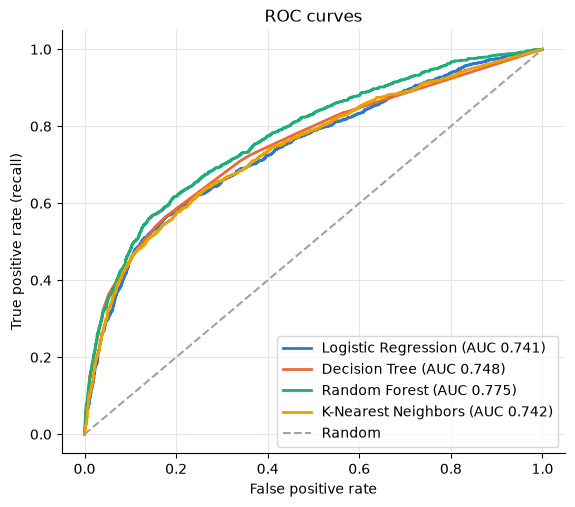

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, searches):
    cm = confusion_matrix(y_test, (probas[name] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap=SEQUENTIAL, cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    ax.set_title(name); ax.grid(False)
plt.suptitle("Confusion matrices (threshold 0.5)", fontweight="bold"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for color, name in zip(SERIES, searches):
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, probas[name]):.3f})")
ax.plot([0, 1], [0, 1], "--", color="#a3a29b", label="Random")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)"); ax.set_title("ROC curves")
ax.legend(loc="lower right"); plt.show()

## 6. Error costs: false positives, false negatives, precision, recall, F1

For the **Credit Portfolio Strategist**, the two error types have very different consequences:

| Error | Meaning | Business impact |
|---|---|---|
| **False negative (FN)** | A customer who **will default** is predicted as safe | Direct credit loss: the exposure is not reduced, no collection action is taken, and portfolio risk is **under-estimated**. Usually the **costlier** error. |
| **False positive (FP)** | A customer who **will not default** is flagged as risky | Opportunity cost: unnecessary limit cuts or interventions and customer dissatisfaction. Portfolio risk is **over-estimated**. |

* **Precision (default class)** = TP / (TP + FP): of the customers flagged as defaulters, the share who really default. Low precision wastes interventions on good customers.
* **Recall (default class)** = TP / (TP + FN): of all real defaulters, the share we catch. Low recall means losses slip through unnoticed.
* **F1-score** = the harmonic mean of precision and recall. It is high only when both are reasonable, which makes it a good single selection criterion for the minority class on imbalanced data.
* **ROC-AUC** measures how well the model *ranks* risky customers above safe ones, independent of the threshold. That is useful for prioritising a portfolio review.

**Why not accuracy?** KNN has the **highest accuracy** in the table above, yet it catches the **fewest defaulters** (lowest recall, most false negatives). On imbalanced data, accuracy rewards predicting the majority class.

### Model selection and decision threshold

Selected model: Random Forest


Decision threshold: 0.5184
{'accuracy': 0.7987, 'precision_1': 0.5453, 'recall_1': 0.5396, 'f1_1': 0.5424, 'roc_auc': 0.7747, 'FP': 597.0, 'FN': 611.0, 'TP': 716.0, 'TN': 4076.0}
                precision    recall  f1-score   support

No default (0)     0.8696    0.8722    0.8709      4673
   Default (1)     0.5453    0.5396    0.5424      1327

      accuracy                         0.7987      6000
     macro avg     0.7075    0.7059    0.7067      6000
  weighted avg     0.7979    0.7987    0.7983      6000



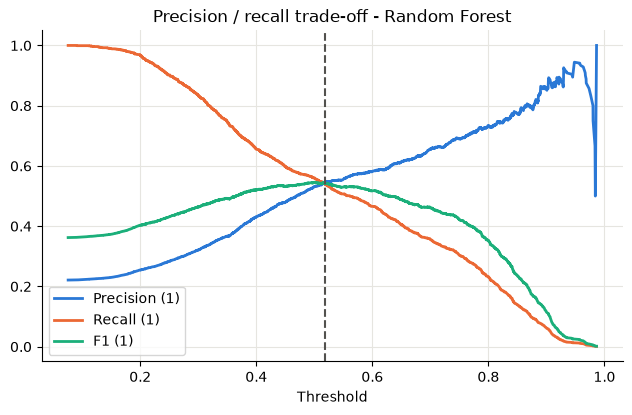

In [17]:
# Select by cross-validated F1 (class 1) -- computed on training folds only, never on the test set.
best_name = comparison["cv_f1"].astype(float).idxmax()
best = searches[best_name].best_estimator_
print("Selected model:", best_name)

# Threshold: maximise F1 on OUT-OF-FOLD predictions of the training set (no test-set peeking).
oof = cross_val_predict(clone(best), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
p, r, t = precision_recall_curve(y_train, oof)
f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
threshold = float(t[np.nanargmax(f1[:-1])])
print(f"Decision threshold: {threshold:.4f}")

tuned = metrics(y_test, probas[best_name], threshold)
print({k: round(float(v), 4) for k, v in tuned.items()})
print(classification_report(y_test, (probas[best_name] >= threshold).astype(int),
                            target_names=["No default (0)", "Default (1)"], digits=4))

p, r, t = precision_recall_curve(y_test, probas[best_name])
f1t = 2 * p * r / np.clip(p + r, 1e-12, None)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(t, p[:-1], color=SERIES[0], lw=2, label="Precision (1)")
ax.plot(t, r[:-1], color=SERIES[1], lw=2, label="Recall (1)")
ax.plot(t, f1t[:-1], color=SERIES[2], lw=2, label="F1 (1)")
ax.axvline(threshold, color="#52514e", ls="--"); ax.set_xlabel("Threshold"); ax.legend()
ax.set_title(f"Precision / recall trade-off - {best_name}"); plt.show()

The threshold is a **business lever**. A strategist who fears losses more than false alarms can **lower** it to raise recall, catching more defaulters at the cost of more false positives, and vice versa. The API returns the raw default probability and a LOW / MEDIUM / HIGH risk band, so the threshold policy stays transparent.

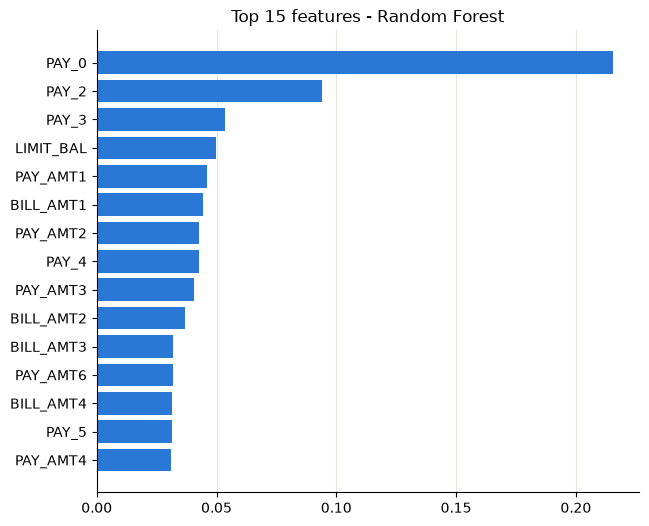

In [18]:
clf = best.named_steps["classifier"]
names = np.array([n.split("__", 1)[-1] for n in best.named_steps["preprocessor"].get_feature_names_out()])
imp = clf.feature_importances_ if hasattr(clf, "feature_importances_") else np.abs(clf.coef_[0])
order = np.argsort(imp)[-15:]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(names[order], imp[order], color=SERIES[0]); ax.set_title(f"Top 15 features - {best_name}")
ax.grid(axis="y", visible=False); plt.show()

### Save the model artifact

In [19]:
metadata = {"model_name": best_name, "model_version": "1.0.0-notebook", "sklearn_version": sklearn.__version__,
            "features": FEATURES, "target": TARGET, "decision_threshold": round(threshold, 4),
            "test_metrics_tuned_threshold": {k: round(float(v), 4) for k, v in tuned.items()}}
joblib.dump({"pipeline": best, "metadata": metadata}, OUTPUT_DIR / "credence_model_notebook.joblib", compress=3)
comparison.to_csv(OUTPUT_DIR / "model_comparison_notebook.csv")
print("Saved to", OUTPUT_DIR.resolve())

Saved to /Users/thapaswireddy/Desktop/Credence AI/notebooks/outputs


## 7. Conclusion

* **Random Forest** is selected. It has the highest cross-validated F1 and the highest ROC-AUC for the default class, and it balances precision and recall better than the other models.
* **Logistic Regression** has the highest recall but many more false positives. **KNN** has the highest accuracy but misses most defaulters, which shows why accuracy alone cannot choose the model.
* **Recent repayment status** (`PAY_0`, `PAY_2`) dominates the predictions, followed by payment amounts and the credit limit.
* The selected pipeline (preprocessing + model) is served by the **FastAPI + MySQL** backend in this project. The strategist uses it to score customers or whole portfolios, store the results, and analyse risk by segment.

*Note:* the production artifact used by the API is produced by `python -m ml.train`, which runs this same pipeline from the project's `ml/` package.